# Central Limit Theorem and Sampling

The **Central Limit Theorem (CLT)** is the reason the normal distribution appears everywhere in statistics, and the reason we can make confident statements about a population from a modest sample.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Central Limit Theorem (CLT)

Let $X_1, X_2, \dots, X_n$ be i.i.d. random variables with mean $\mu$ and variance $\sigma^2 < \infty$. Then the standardized sample mean

$$
Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}}
$$

converges in distribution to the standard normal $N(0,1)$ as $n \to \infty$ — **regardless of the shape of the population distribution**.

Two practical consequences:
- The sample mean $\bar{X}$ is approximately $N\!\left(\mu, \frac{\sigma^2}{n}\right)$ for large $n$.
- The **standard error** of the mean shrinks with the square root of the sample size:
$$
SE(\bar{X}) = \frac{\sigma}{\sqrt{n}}
$$

## 2. Sampling

Sampling is the process of selecting a subset (sample) from a population to estimate population characteristics.
- **Simple random sampling** gives each member an equal chance of selection.
- **Stratified sampling** samples separately within groups (strata) to guarantee each group is represented.
- The **sampling distribution** is the distribution of a statistic (e.g., the mean) over many repeated samples.

In [2]:
set.seed(42)

# Population: Exponential distribution (strongly right-skewed, NOT normal)
population <- rexp(100000, rate = 1)  # mean = 1, variance = 1
cat("Population mean:", round(mean(population), 3), " | sd:", round(sd(population), 3), "\n")

generate_sample_means <- function(sample_size, num_samples) {
  replicate(num_samples, mean(sample(population, sample_size)))
}

sample_sizes <- c(2, 5, 30, 100)
num_samples <- 5000
means_list <- lapply(sample_sizes, generate_sample_means, num_samples = num_samples)

Population mean: 0.998  | sd: 1.001 


In [3]:
skew <- function(x) mean((x - mean(x))^3) / sd(x)^3
res <- data.frame(
  n = sample_sizes,
  mean_of_means = sapply(means_list, mean),
  observed_SE   = sapply(means_list, sd),
  theoretical_SE = sd(population) / sqrt(sample_sizes),
  skewness = sapply(means_list, skew)
)
print(round(res, 4), row.names = FALSE)

   n mean_of_means observed_SE theoretical_SE skewness
   2        1.0066      0.7132         0.7075   1.4182
   5        0.9892      0.4491         0.4475   0.9122
  30        1.0008      0.1832         0.1827   0.3406
 100        0.9975      0.0987         0.1001   0.2121


*Insight: The mean of the sample means stays at about 1 (the population mean) for every $n$, the observed standard error matches $\sigma/\sqrt{n}$ almost exactly, and the skewness drops toward 0 (symmetry) as $n$ grows. That's the CLT in one table.*

## 3. Visualizing the CLT

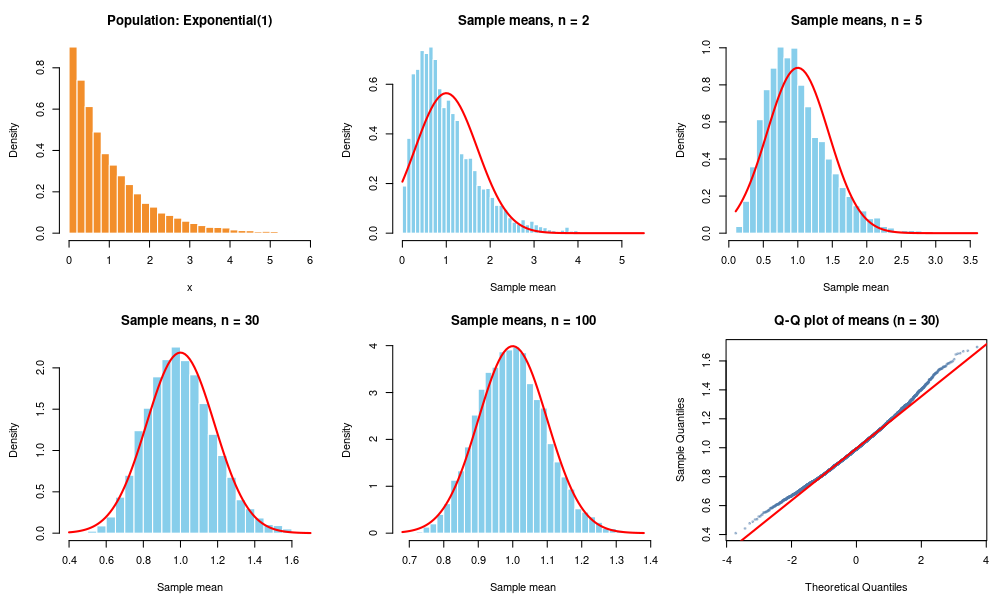

In [4]:
par(mfrow = c(2, 3), mar = c(4.5, 4.5, 3, 1))

hist(population[1:20000], breaks = 60, probability = TRUE, col = "#F28E2B", border = "white",
     main = "Population: Exponential(1)", xlab = "x", xlim = c(0, 6))

for (i in seq_along(sample_sizes)) {
  hist(means_list[[i]], breaks = 40, probability = TRUE, col = "skyblue", border = "white",
       main = paste("Sample means, n =", sample_sizes[i]), xlab = "Sample mean")
  curve(dnorm(x, mean = 1, sd = 1 / sqrt(sample_sizes[i])), col = "red", lwd = 2, add = TRUE)
}

qqnorm(means_list[[3]], pch = 19, cex = 0.4, col = adjustcolor("#4E79A7", 0.4),
       main = "Q-Q plot of means (n = 30)")
qqline(means_list[[3]], col = "red", lwd = 2)

The red curve is the normal distribution the CLT predicts, $N(1, 1/n)$. For $n=2$ the means are still clearly skewed; by $n = 30$ the fit is close, and at $n=100$ it is nearly perfect.

## 4. Standard Error vs Sample Size

Because $SE = \sigma / \sqrt{n}$, to **halve** the uncertainty you need **four times** as much data.

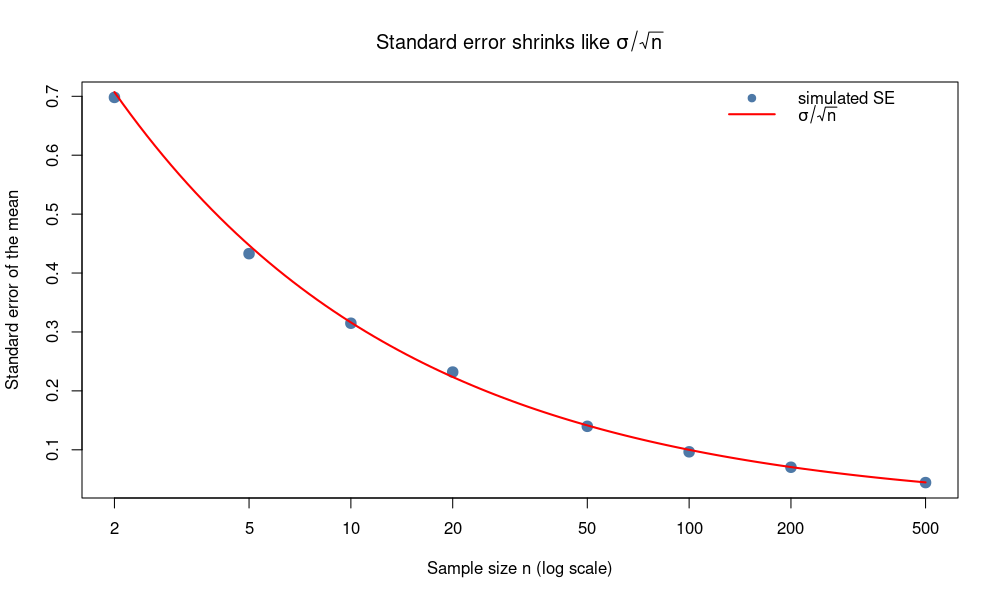

In [5]:
ns <- c(2, 5, 10, 20, 50, 100, 200, 500)
obs_se <- sapply(ns, function(n) sd(generate_sample_means(n, 2000)))

par(mfrow = c(1, 1))
plot(ns, obs_se, log = "x", pch = 19, cex = 1.4, col = "#4E79A7",
     main = expression("Standard error shrinks like" ~ sigma / sqrt(n)),
     xlab = "Sample size n (log scale)", ylab = "Standard error of the mean")
curve(1 / sqrt(x), add = TRUE, col = "red", lwd = 2)
legend("topright", c("simulated SE", expression(sigma / sqrt(n))), col = c("#4E79A7", "red"),
       pch = c(19, NA), lty = c(NA, 1), lwd = c(NA, 2), bty = "n")

## 5. Confidence Intervals: What "95%" Really Means

A 95% confidence interval $\bar{x} \pm 1.96 \cdot \frac{s}{\sqrt{n}}$ is built by a procedure that **captures the true mean in 95% of repeated samples**. It does *not* mean there's a 95% chance the true mean is in one particular interval. Let's draw 100 samples and check.

Intervals containing the true mean: 93 out of 100


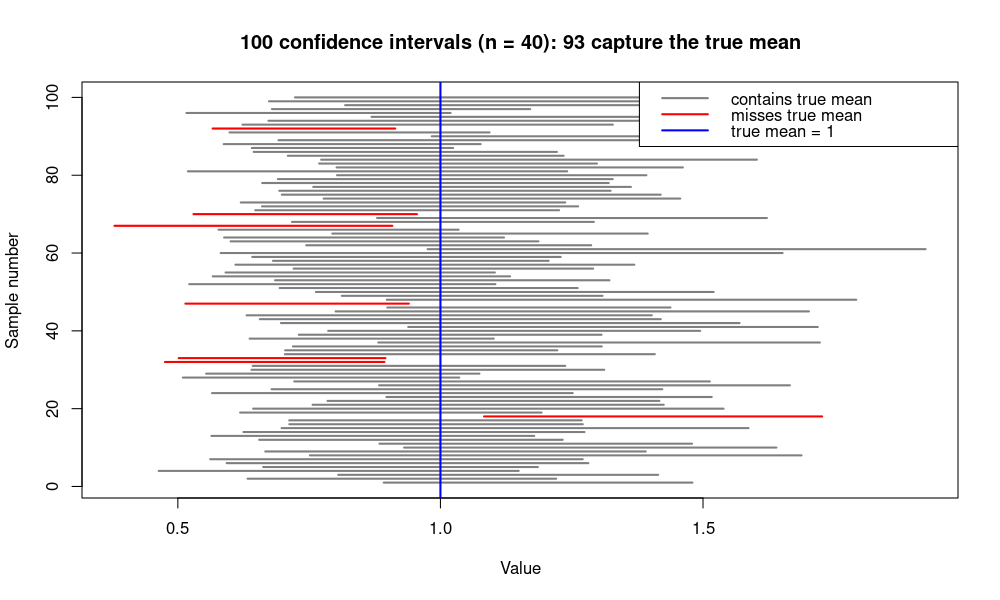

In [6]:
set.seed(11)
n <- 40; true_mu <- 1
cis <- t(replicate(100, {
  s <- sample(population, n)
  mean(s) + c(-1, 1) * qt(0.975, n - 1) * sd(s) / sqrt(n)
}))
covered <- cis[, 1] <= true_mu & cis[, 2] >= true_mu
cat("Intervals containing the true mean:", sum(covered), "out of 100\n")

plot(NA, xlim = range(cis), ylim = c(1, 100), xlab = "Value", ylab = "Sample number",
     main = sprintf("100 confidence intervals (n = %d): %d capture the true mean", n, sum(covered)))
segments(cis[, 1], 1:100, cis[, 2], 1:100, col = ifelse(covered, "grey50", "red"), lwd = 2)
abline(v = true_mu, col = "blue", lwd = 2)
legend("topright", c("contains true mean", "misses true mean", "true mean = 1"),
       col = c("grey50", "red", "blue"), lwd = 2, bg = "white")

## Real-World Use Case or Analogy

Think of measuring the average height of students from different classes:
- Small class ($n = 5$): the class average varies a lot from class to class, and its distribution is irregular.
- Large class ($n = 100$): class averages cluster tightly around the true population mean and form a bell curve.

Election polls rely on exactly this: a well-drawn random sample of about 1,000 voters gives a margin of error of roughly ±3 percentage points, whether the country has 5 million or 300 million voters — because the standard error depends on the **sample size**, not the population size.